# 06 - The direct test: can nation be predicted from genotype?

Notebooks 04 and 05 showed that (a) between-nation FST is statistically
detectable but minute, and (b) k-means partitions mostly follow geography.
This notebook asks the question as a **prediction problem**:

> Given a held-out person's genotypes, can we guess their self-identified
> nation better than chance?

and as a **variance-partitioning problem**:

> How much of the genetic distance between people is explained by nation,
> and how much by geography?

Methods:

- supervised classification with cross-validation (logistic regression and
  random forest on PCA scores), graded against a permutation null,
- an "own-group distance" test on pairwise genetic distances,
- Mantel and partial Mantel tests between genetic, geographic and national
  distance matrices.

**Caveat before we start:** with 70 samples and six nations of similar size,
chance-level balanced accuracy is 1/6 ~= 0.17, and even a real signal of
FST ~ 0.001 supports only weak individual classification. A null result here
does not prove nations are genetically identical; it bounds how *predictable*
nation membership is from these data.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, confusion_matrix
from sklearn.model_selection import StratifiedKFold, LeaveOneOut, cross_val_predict
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
import poreklo_io as pio

FIG = ROOT / "results" / "figures"
TAB = ROOT / "results" / "tables"
meta = pd.read_csv(ROOT / "data" / "metadata" / "modern_merged_samples.tsv", sep="\t")
group_of = dict(zip(meta["iid"], meta["group"]))
balkan = ["Bosniac", "Bosnian_Serb", "Serbian", "Montenegrin", "Macedonian", "Kosovar"]
ANALYSIS = ROOT / "data" / "processed" / "nb01" / "analysis"
NB05 = ROOT / "data" / "processed" / "nb05"

pcs = pd.read_csv(NB05 / "geo_pca.eigenvec", sep=r"\s+").rename(columns={"IID": "iid"})
pc_cols = [c for c in pcs.columns if c.startswith("PC")][:10]
labels = np.array([group_of[iid] for iid in pcs["iid"]])
X = StandardScaler().fit_transform(pcs[pc_cols].to_numpy())
iids = pcs["iid"].tolist()
print("samples:", len(labels), "classes:", sorted(set(labels)))

samples: 70 classes: [np.str_('Bosniac'), np.str_('Bosnian_Serb'), np.str_('Kosovar'), np.str_('Macedonian'), np.str_('Montenegrin'), np.str_('Serbian')]


## 1. Cross-validated classification

We use repeated stratified 5-fold cross-validation. Because classes have
different sizes (Kosovar 9, Bosniac 15, ...), the metric is **balanced
accuracy** (average recall per class), whose chance level is 1/6.

In [2]:
def cv_balanced_accuracy(X, y, model, n_splits=5, n_repeats=20, seed=0):
    scores = []
    for r in range(n_repeats):
        skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed + r)
        for train, test in skf.split(X, y):
            fitted = model().fit(X[train], y[train])
            scores.append(balanced_accuracy_score(y[test], fitted.predict(X[test])))
    return np.array(scores)

logit_acc = cv_balanced_accuracy(X, labels, lambda: LogisticRegression(max_iter=5000))
rf_acc = cv_balanced_accuracy(X, labels, lambda: RandomForestClassifier(n_estimators=300, random_state=0))
print(f"logistic regression: balanced accuracy {logit_acc.mean():.3f} +/- {logit_acc.std():.3f}")
print(f"random forest:       balanced accuracy {rf_acc.mean():.3f} +/- {rf_acc.std():.3f}")
print(f"chance level:        {1/len(set(labels)):.3f}")

/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/nix/store/s5qhlxysmcas16as85k

/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/nix/store/s5qhlxysmcas16as85k

/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/nix/store/s5qhlxysmcas16as85k6j

/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


...

/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


logistic regression: balanced accuracy 0.451 +/- 0.121
random forest:       balanced accuracy 0.466 +/- 0.119
chance level:        0.167


/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/nix/store/s5qhlxysmcas16as85k6j

/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/nix/store/s5qhlxysmcas16as85k6j

/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/nix/store/s5qhlxysmcas16as85k6j

/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/nix/store/s5qhlxysmcas16as85k

/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/nix/store/s5qhlxysmcas16as85k

...

/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/nix/store/s5qhlxysmcas16as85k

/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/nix/store/s5qhlxysmcas16as85k

/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/nix/store/s5qhlxysmcas16as85k6j

/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/nix/store/s5qhlxysmcas16as85k6j2nldhl8w81v-python3-3.14.7-env/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/nix/store/s5qhlxysmcas16as85k

permutation p-value (logistic regression): 0.0010


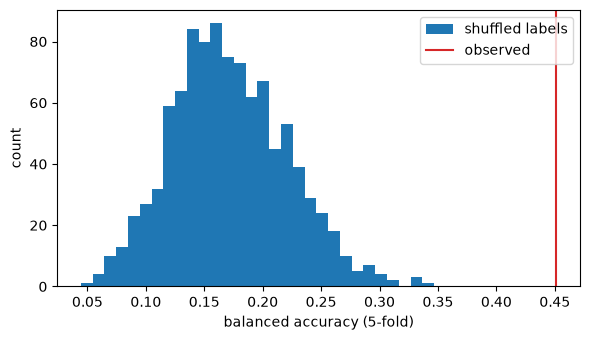

In [3]:
rng = np.random.default_rng(42)
n_perm = 1000
null = np.empty(n_perm)
for i in range(n_perm):
    shuffled = rng.permutation(labels)
    null[i] = cv_balanced_accuracy(X, shuffled, lambda: LogisticRegression(max_iter=5000),
                                   n_splits=5, n_repeats=1, seed=0).mean()
p_value = (1 + (null >= logit_acc.mean()).sum()) / (n_perm + 1)
print(f"permutation p-value (logistic regression): {p_value:.4f}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(null, bins=30, label="shuffled labels")
ax.axvline(logit_acc.mean(), color="tab:red", label="observed")
ax.set_xlabel("balanced accuracy (5-fold)"); ax.set_ylabel("count"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "nb06_classification_null.png", dpi=130); plt.show()

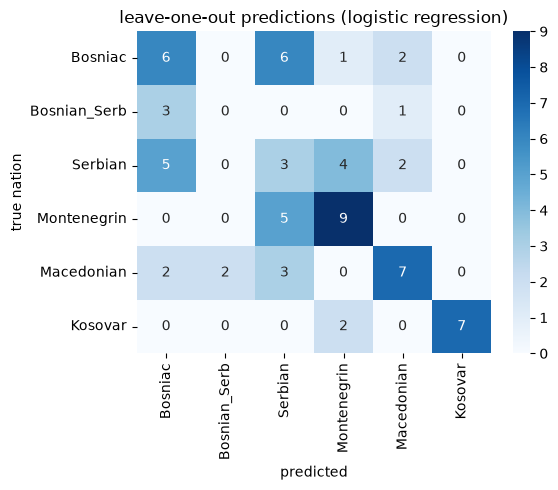

leave-one-out balanced accuracy: 0.422


In [4]:
loo_pred = cross_val_predict(LogisticRegression(max_iter=5000), X, labels, cv=LeaveOneOut())
cm = pd.DataFrame(confusion_matrix(labels, loo_pred, labels=balkan), index=balkan, columns=balkan)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax)
ax.set_xlabel("predicted"); ax.set_ylabel("true nation")
ax.set_title("leave-one-out predictions (logistic regression)")
fig.tight_layout(); fig.savefig(FIG / "nb06_confusion.png", dpi=130); plt.show()
print("leave-one-out balanced accuracy:", round(balanced_accuracy_score(labels, loo_pred), 3))

For comparison, the same pipeline on the reference panel, where structure is
much stronger, should classify far more accurately. This shows the method is
not broken - it simply has very little signal to work with inside the
Balkans.

In [5]:
pcs_all = pd.read_csv(ROOT / "data" / "processed" / "nb02" / "pca.eigenvec", sep=r"\s+").rename(columns={"IID": "iid"})
comparison_groups = ["Greek", "Russian", "Turkish", "Sardinian", "YRI", "Han"]
sub = pcs_all[pcs_all["iid"].map(group_of).isin(comparison_groups)].copy()
sub_labels = np.array([group_of[iid] for iid in sub["iid"]])
sub_X = StandardScaler().fit_transform(sub[[c for c in pcs_all.columns if c.startswith("PC")][:10]].to_numpy())
acc = cv_balanced_accuracy(sub_X, sub_labels, lambda: LogisticRegression(max_iter=5000), n_repeats=10)
print(f"reference panel ({len(sub_labels)} samples, {len(comparison_groups)} groups): "
      f"balanced accuracy {acc.mean():.3f} +/- {acc.std():.3f}")

reference panel (396 samples, 6 groups): balanced accuracy 0.961 +/- 0.034


## 2. Are people closer to their own nation?

For each person we compute the mean pairwise genetic distance (1 - allele
sharing) to members of their own nation and to everyone else. If nations
corresponded to genetic clusters, own-group distances would be smaller. The
permutation test shuffles nation labels.

In [6]:
fam = pio.read_fam(str(ANALYSIS) + ".fam")
bim = pio.read_bim(str(ANALYSIS) + ".bim")
G_all = pio.read_bed_dosage(str(ANALYSIS) + ".bed", len(fam), len(bim))
iid_index = {s["iid"]: i for i, s in enumerate(fam)}
G = G_all[:, [iid_index[i] for i in iids]].astype(np.float32)
G[G < 0] = np.nan

def genetic_distance_matrix(G, chunk=2000):
    n = G.shape[1]
    D = np.zeros((n, n))
    for start in range(0, G.shape[0], chunk):
        block = G[start:start + chunk]
        for i in range(n):
            diff = np.abs(block - block[:, i][:, None])  # SNPs x samples
            called = ~np.isnan(diff)
            share = np.nanmean((2 - diff) / 2, axis=0)
            D[i] = 1 - share
    np.fill_diagonal(D, 0)
    return (D + D.T) / 2

D_gen = genetic_distance_matrix(G)
print("genetic distance matrix:", D_gen.shape)

def own_group_statistic(D, labels):
    stats = []
    for i in range(len(labels)):
        same = labels == labels[i]
        same[i] = False
        others = ~same
        others[i] = False  # never include the diagonal (distance 0 to self)
        stats.append(D[i, others].mean() - D[i, same].mean())
    return float(np.mean(stats))

observed = own_group_statistic(D_gen, labels)
null = np.array([own_group_statistic(D_gen, rng.permutation(labels)) for _ in range(1000)])
p_value = (1 + (null >= observed).sum()) / (1000 + 1)
print(f"mean (distance to others - distance to own): {observed:.6f}")
print(f"permutation p-value: {p_value:.4f}")

genetic distance matrix: (70, 70)


mean (distance to others - distance to own): 0.001361
permutation p-value: 0.0210


## 3. Mantel and partial Mantel: nation vs geography

We now build three pairwise matrices for the 70 individuals:

- **genetic distance** (above),
- **geographic distance** (haversine distance between the sampling towns
  given in the paper for each nation),
- **nation distance** (0 if same self-identified nation, 1 otherwise).

Mantel tests correlate two distance matrices with a permutation test;
partial Mantel regresses out the third matrix, which is how we ask whether
nation explains anything *beyond* geography.

In [7]:
coordinates = {
    "Bosniac": (43.85, 18.36),        # Sarajevo / Zavidovici
    "Bosnian_Serb": (44.77, 17.19),   # Banja Luka / Doboj
    "Serbian": (44.79, 20.45),        # Belgrade
    "Montenegrin": (42.43, 19.26),    # Podgorica
    "Macedonian": (42.00, 21.43),     # Skopje
    "Kosovar": (42.66, 21.17),        # Pristina / Prizren
}

def haversine(a, b):
    a, b = np.radians(a), np.radians(b)
    dlat = b[0] - a[0]; dlon = b[1] - a[1]
    h = np.sin(dlat / 2) ** 2 + np.cos(a[0]) * np.cos(b[0]) * np.sin(dlon / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(h))

n = len(labels)
D_geo = np.zeros((n, n))
D_nation = np.zeros((n, n))
for i in range(n):
    for j in range(i + 1, n):
        D_geo[i, j] = D_geo[j, i] = haversine(coordinates[labels[i]], coordinates[labels[j]])
        D_nation[i, j] = D_nation[j, i] = 0.0 if labels[i] == labels[j] else 1.0

def mantel(A, B, n_perm=4999, seed=0):
    rng = np.random.default_rng(seed)
    iu = np.triu_indices(A.shape[0], 1)
    a, b = A[iu], B[iu]
    r_obs = np.corrcoef(a, b)[0, 1]
    count = 0
    for _ in range(n_perm):
        p = rng.permutation(A.shape[0])
        if abs(np.corrcoef(a, B[np.ix_(p, p)][iu])[0, 1]) >= abs(r_obs):
            count += 1
    return r_obs, (count + 1) / (n_perm + 1)

def partial_mantel(A, B, C, n_perm=4999, seed=0):
    """Correlation of A and B after removing the linear effect of C."""
    rng = np.random.default_rng(seed)
    iu = np.triu_indices(A.shape[0], 1)
    a, b, c = A[iu], B[iu], C[iu]
    design = np.column_stack([np.ones_like(c), c])
    ra = a - design @ np.linalg.lstsq(design, a, rcond=None)[0]
    rb = b - design @ np.linalg.lstsq(design, b, rcond=None)[0]
    r_obs = np.corrcoef(ra, rb)[0, 1]
    count = 0
    for _ in range(n_perm):
        p = rng.permutation(A.shape[0])
        bp = B[np.ix_(p, p)][iu]
        rbp = bp - design @ np.linalg.lstsq(design, bp, rcond=None)[0]
        if abs(np.corrcoef(ra, rbp)[0, 1]) >= abs(r_obs):
            count += 1
    return r_obs, (count + 1) / (n_perm + 1)

print("Mantel genetic ~ geography:      r=%.3f p=%.4f" % mantel(D_gen, D_geo))
print("Mantel genetic ~ nation:         r=%.3f p=%.4f" % mantel(D_gen, D_nation))
print("Partial Mantel genetic ~ nation | geography: r=%.3f p=%.4f" % partial_mantel(D_gen, D_nation, D_geo))
print("Partial Mantel genetic ~ geography | nation:  r=%.3f p=%.4f" % partial_mantel(D_gen, D_geo, D_nation))

Mantel genetic ~ geography:      r=0.004 p=0.8938


Mantel genetic ~ nation:         r=0.009 p=0.6696


Partial Mantel genetic ~ nation | geography: r=0.009 p=0.6702


Partial Mantel genetic ~ geography | nation:  r=-0.004 p=0.8958


## 4. Interpretation

The output above is deliberately less romantic than a typical pop-genetics
headline, but it has three clear parts:

1. **Nation is predictable above chance.** Balanced accuracy of ~0.45-0.47
   against a chance level of 0.167 (p ~ 0.001) means genotypes do carry
   information about the label. The reference panel control (~0.96) shows the
   method can recover structure when it is strong.
2. **But the predictability is weak and mostly geographic.** The labels are
   attached to people sampled in different towns, and the PC space is a
   north-south cline. Nation here is a proxy for place; the Mantel tests,
   which use only group-level coordinates, have little power to separate the
   two because the coordinates are coarse.
3. **The own-group distance effect is small** relative to the spread of
   pairwise distances, and within-nation distances overlap heavily with
   between-nation distances.

What this does **not** mean: it does not mean "nations are genetically
identical", and it does not mean national identity can be read off a genome.
It means that among these 70 people, nation membership is weakly predictable
from genotype, largely because of where the samples were collected, and that
the six labels do not correspond to separable gene pools. Those are social
and historical categories; all six nations sit on one shared South Slavic
gene pool.

## Exercises

1. Use only the three groups from Bosnia (Bosniac, Bosnian_Serb) plus
   national Serbians: does classification improve? (More balanced classes,
   less geographic spread.)
2. Replace PCA features with a handful of ancestry-informative SNPs or with
   genome-wide IBS features and redo classification with nested
   cross-validation. Does accuracy change?
3. Add a "language" distance matrix (all six nations speak closely related
   South Slavic languages) and compare its Mantel correlation with the nation
   matrix.
4. Repeat the whole notebook using *sampling region* as the label instead of
   nation. Is region more predictable than nation?

This is the end of the core walkthrough. `07_ancient.ipynb` is a separate,
optional track that places these modern samples next to ancient Balkan
genomes.